#  9-1 Introduction to Consumer Analysis and CRM in Marketing Practice Questions Solutions

In [1]:
# The following libraries are used, so please load them beforehand
import numpy as np
import pandas as pd

import datetime

# Visualization library
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
%matplotlib inline

# Displayed to 3 decimal places
%precision 3

'%.3f'

In [2]:
# Download the data from the UCI website
!wget "http://archive.ics.uci.edu/static/public/352/online+retail.zip"
# Extract the downloaded data.
!unzip "./online+retail.zip"
# Load the extracted Excel data.
file_url = './Online Retail.xlsx'
all_online_retail_data = pd.ExcelFile(file_url)

--2026-11-22 06:14:22--  http://archive.ics.uci.edu/static/public/352/online+retail.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘online+retail.zip’

online+retail.zip       [          <=>       ]  22.62M  12.0MB/s    in 1.9s    

2026-11-22 06:14:24 (12.0 MB/s) - ‘online+retail.zip’ saved [23715478]

Archive:  ./online+retail.zip
 extracting: Online Retail.xlsx      


In [3]:
# Specify a sheet in an Excel file
online_retail_data_table = all_online_retail_data.parse('Online Retail')

In [4]:
online_retail_data_table['cancel_flg'] = online_retail_data_table.InvoiceNo.map(lambda x: str(x)[0])

In [5]:
online_retail_data_table = online_retail_data_table[(
    online_retail_data_table.cancel_flg == '5') & (online_retail_data_table.CustomerID.notnull())]

In [6]:
online_retail_data_table.CustomerID = online_retail_data_table.CustomerID.astype(int)

In [7]:
tmp_online_retail_data_table = online_retail_data_table.copy()
tmp_online_retail_data_table = tmp_online_retail_data_table[(tmp_online_retail_data_table.CustomerID.notnull())]
tmp_online_retail_data_table.CustomerID = tmp_online_retail_data_table.CustomerID.astype(int)
tmp_online_retail_data_table.info()

<class 'pandas.core.frame.DataFrame'>
Index: 397924 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397924 non-null  object        
 1   StockCode    397924 non-null  object        
 2   Description  397924 non-null  object        
 3   Quantity     397924 non-null  int64         
 4   InvoiceDate  397924 non-null  datetime64[ns]
 5   UnitPrice    397924 non-null  float64       
 6   CustomerID   397924 non-null  int64         
 7   Country      397924 non-null  object        
 8   cancel_flg   397924 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(5)
memory usage: 30.4+ MB


#### <Practice Question 9-1-1>
1.   Check the period of the data to see if it matches the description from UCI. Implement it in Python and verify the results.
2.   There is a column called `Country`. Count the number of records for each country.
3.   Calculate the total sales amount for each country, create a ranking table, and then plot it as a bar graph.

#### Answer

In [8]:
print("From {0} to {1}".format(online_retail_data_table.InvoiceDate.min(), online_retail_data_table.InvoiceDate.max()))

From 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [9]:
online_retail_data_table.groupby(["Country"])["InvoiceNo"].count().sort_values(ascending=False)

,InvoiceNo
Country,
United Kingdom,354345
Germany,9042
France,8342
EIRE,7238
Spain,2485
Netherlands,2363
Belgium,2031
Switzerland,1842
Portugal,1462


The total sales purchase amount column will be added.

In [10]:
online_retail_data_table['TotalPrice'] = online_retail_data_table.Quantity * online_retail_data_table.UnitPrice

In [11]:
rank_tp_df = online_retail_data_table.groupby(["Country"])["TotalPrice"].sum().sort_values(ascending=False)
rank_tp_df

,TotalPrice
Country,
United Kingdom,7308391.554
Netherlands,285446.340
EIRE,265545.900
Germany,228867.140
France,209024.050
Australia,138521.310
Spain,61577.110
Switzerland,56443.950
Belgium,41196.340


The bar chart displayed below shows the sales ranking by country. As expected, the UK has significantly higher sales

Text(0.5, 0, 'country')

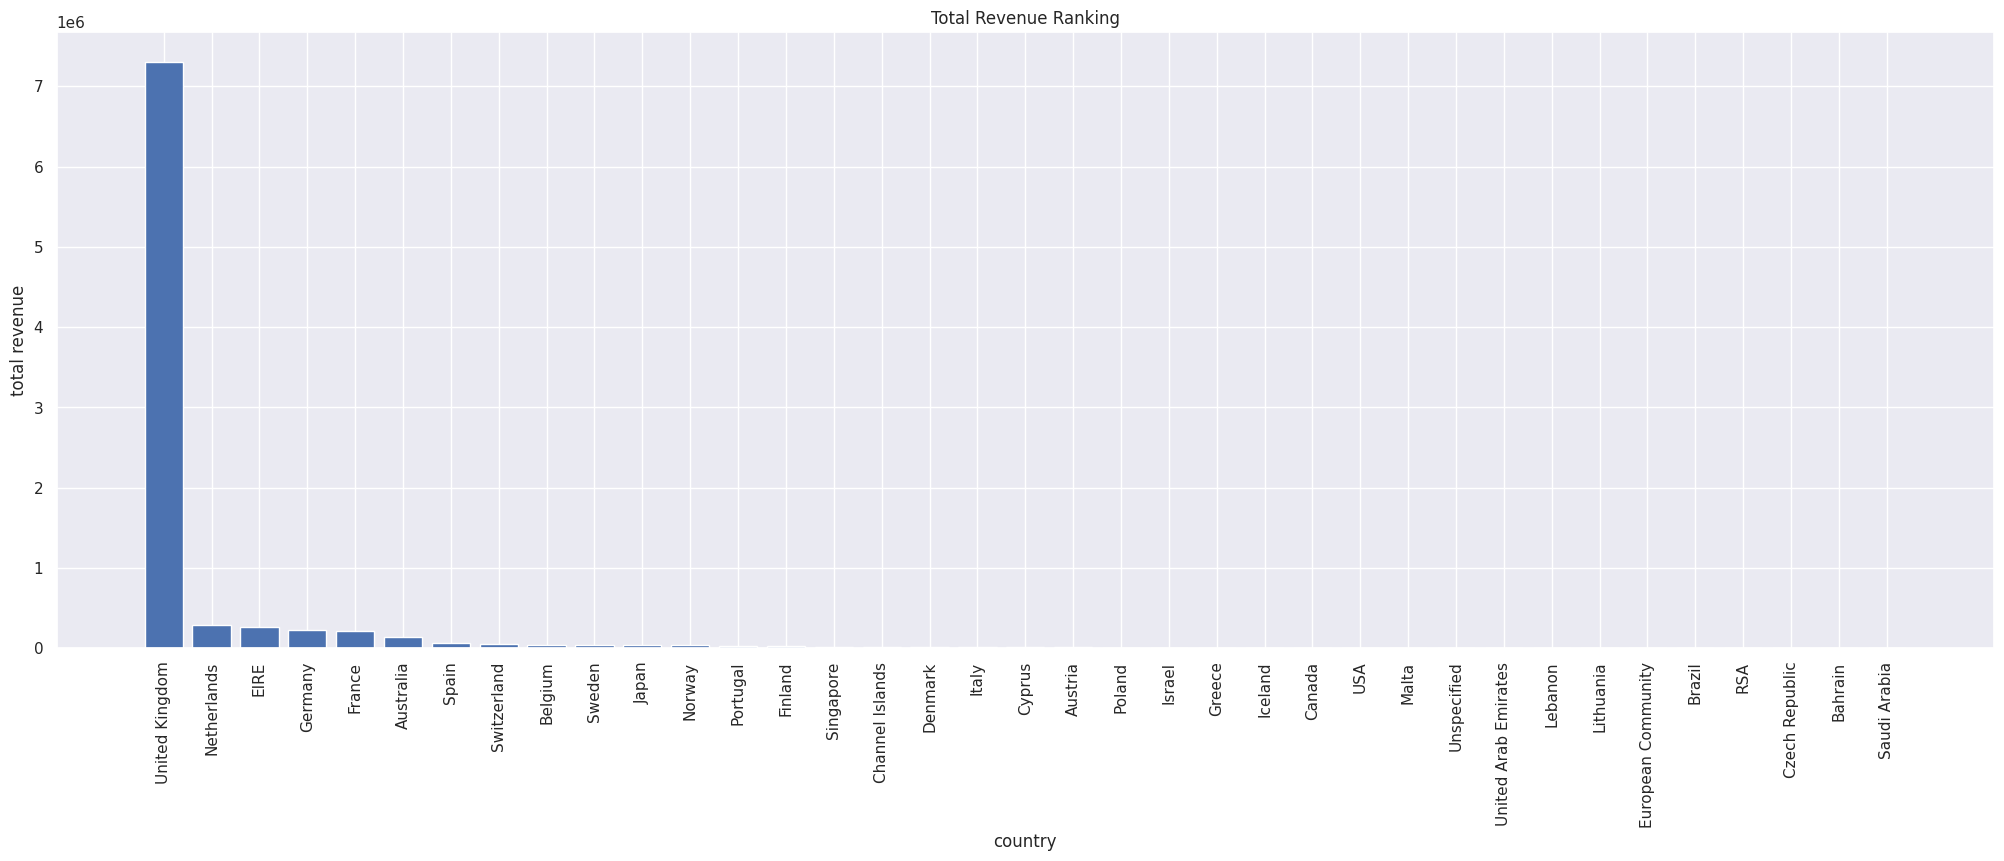

In [12]:
plt.figure(figsize=(25,8))
plt.xticks(rotation=90)
plt.bar(rank_tp_df.index, rank_tp_df,)
plt.title('Total Revenue Ranking')
plt.ylabel('total revenue')
plt.xlabel('country')

#### <Practice Question 9-1-2>
1. Which customer has the most number of shopping transactions (baskets) in this data?
2. Which customer has the highest total purchase amount in this data?
3. Which product (based on `StockCode`) has the highest sales quantity in this data?
4. Which product (based on `StockCode`) has the highest total sales amount in this data?
5. In this data, the count of unique items based on product name is higher than the unique count based on `StockCode`. Consider a hypothesis for this discrepancy and implement (verify) it to confirm.

#### Answer

In [13]:
cust_invoice_rank_df = online_retail_data_table.groupby(['CustomerID'])['InvoiceNo'].nunique().sort_values(ascending=False)
cust_invoice_rank_df.head(1)

,InvoiceNo
CustomerID,
12748,210


In [14]:
cust_total_p_rank_df = online_retail_data_table.groupby(['CustomerID'])['TotalPrice'].sum().sort_values(ascending=False)
cust_total_p_rank_df.head(1)

,TotalPrice
CustomerID,
14646,280206.02


In [15]:
stock_total_cnt_rank_df = online_retail_data_table.groupby(['StockCode'])['Quantity'].sum().sort_values(ascending=False)
stock_total_cnt_rank_df.head(1)

,Quantity
StockCode,
23843,80995


In [16]:
stock_total_p_rank_df = online_retail_data_table.groupby(['StockCode'])['TotalPrice'].sum().sort_values(ascending=False)
stock_total_p_rank_df.head(1)

,TotalPrice
StockCode,
23843,168469.6


There is an issue where the number of product codes does not match the number of product names. This means that even the same product code may have several different product names associated with it. Consider this, assuming there is no error in the data.

The hypothesis could be that there was a change in product names over time, or perhaps product names differ by country. This is a plausible assumption but requires verification through hypothesis testing. Let's implement the following to verify:

The implementation below counts how many different product names exist for each `StockCode`. Normally, the count should be 1, but if multiple names exist for the same `StockCode`, the count will be 2 or more.

In [17]:
online_retail_data_table.groupby(["StockCode"])["Description"].nunique().sort_values(ascending=False)

,Description
StockCode,
23236,4
23196,4
23370,3
23209,3
23126,3
...,...
22428,1
22429,1
22430,1


For example, let's focus on the `StockCode` 23236 at the top.

In [18]:
target_stock_df = online_retail_data_table[online_retail_data_table.StockCode==23236]
target_stock_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,cancel_flg,TotalPrice
218408,556042,23236,DOILEY STORAGE TIN,2,2011-06-08 12:44:00,2.89,14367,United Kingdom,5,5.78
218586,556056,23236,DOILEY STORAGE TIN,1,2011-06-08 13:35:00,2.89,17841,United Kingdom,5,2.89
219658,556106,23236,DOILEY STORAGE TIN,2,2011-06-08 16:54:00,2.89,14056,United Kingdom,5,5.78
220367,556187,23236,DOILEY STORAGE TIN,6,2011-06-09 11:49:00,2.89,15296,United Kingdom,5,17.34
220493,556195,23236,DOILEY STORAGE TIN,6,2011-06-09 12:21:00,2.89,16745,United Kingdom,5,17.34
...,...,...,...,...,...,...,...,...,...,...
534004,581126,23236,STORAGE TIN VINTAGE DOILY,6,2011-12-07 12:43:00,2.89,18272,United Kingdom,5,17.34
534688,581166,23236,STORAGE TIN VINTAGE DOILY,1,2011-12-07 14:43:00,2.89,15525,United Kingdom,5,2.89
534700,581166,23236,STORAGE TIN VINTAGE DOILY,2,2011-12-07 14:43:00,2.89,15525,United Kingdom,5,5.78
534738,581166,23236,STORAGE TIN VINTAGE DOILY,2,2011-12-07 14:43:00,2.89,15525,United Kingdom,5,5.78


Let's display all the raw data, as there are around 300 records in total. The following code changed on the Pandas settings to allow up to 300 rows to be displayed.

In [19]:
pd.set_option('display.max_rows', 300)

Looking at the data, it appears that from June to the first half of August 2011, the product was named "DOILEY STORAGE TIN," but after that, the name changed to "STORAGE TIN VINTAGE DOILY." It seems that there are no changes in the name based on the country. However, this is only a hypothesis, so if there are any information sources to verify this, it would be necessary to check them. By narrowing down the data with a hypothesis and examining the raw data, you can confirm such details. This kind of careful work should be done on a case-by-case basis.

In [20]:
target_stock_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,cancel_flg,TotalPrice
218408,556042,23236,DOILEY STORAGE TIN,2,2011-06-08 12:44:00,2.89,14367,United Kingdom,5,5.78
218586,556056,23236,DOILEY STORAGE TIN,1,2011-06-08 13:35:00,2.89,17841,United Kingdom,5,2.89
219658,556106,23236,DOILEY STORAGE TIN,2,2011-06-08 16:54:00,2.89,14056,United Kingdom,5,5.78
220367,556187,23236,DOILEY STORAGE TIN,6,2011-06-09 11:49:00,2.89,15296,United Kingdom,5,17.34
220493,556195,23236,DOILEY STORAGE TIN,6,2011-06-09 12:21:00,2.89,16745,United Kingdom,5,17.34
220496,556196,23236,DOILEY BISCUIT TIN,6,2011-06-09 12:27:00,2.89,18065,United Kingdom,5,17.34
220640,556205,23236,DOILEY STORAGE TIN,6,2011-06-09 13:37:00,2.89,15827,United Kingdom,5,17.34
220648,556206,23236,DOILEY BISCUIT TIN,6,2011-06-09 13:46:00,2.89,14911,EIRE,5,17.34
221696,556263,23236,DOILEY STORAGE TIN,2,2011-06-09 18:41:00,2.89,13969,United Kingdom,5,5.78
221917,556290,23236,DOILEY STORAGE TIN,6,2011-06-10 09:23:00,2.89,17088,United Kingdom,5,17.34


#### <Practice Question 9-1-3>
1.   Let's calculate the PI value for other products

(Answer omitted)

#### <Practice Question 9-1-4>

1.   Calculate the total sales by hour from the data above and plot it on a graph.
2.   Furthermore, identify the hour with the highest sales and investigate what product sold the most and which customer purchased it.

In [21]:
online_retail_data_table.set_index(['InvoiceDate'],inplace=True)

#### Answer

/tmp/ipykernel_640/2626896527.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  online_retail_data_table['TotalPrice'].resample('H').sum().plot(figsize=(15,6))


<Axes: xlabel='InvoiceDate'>

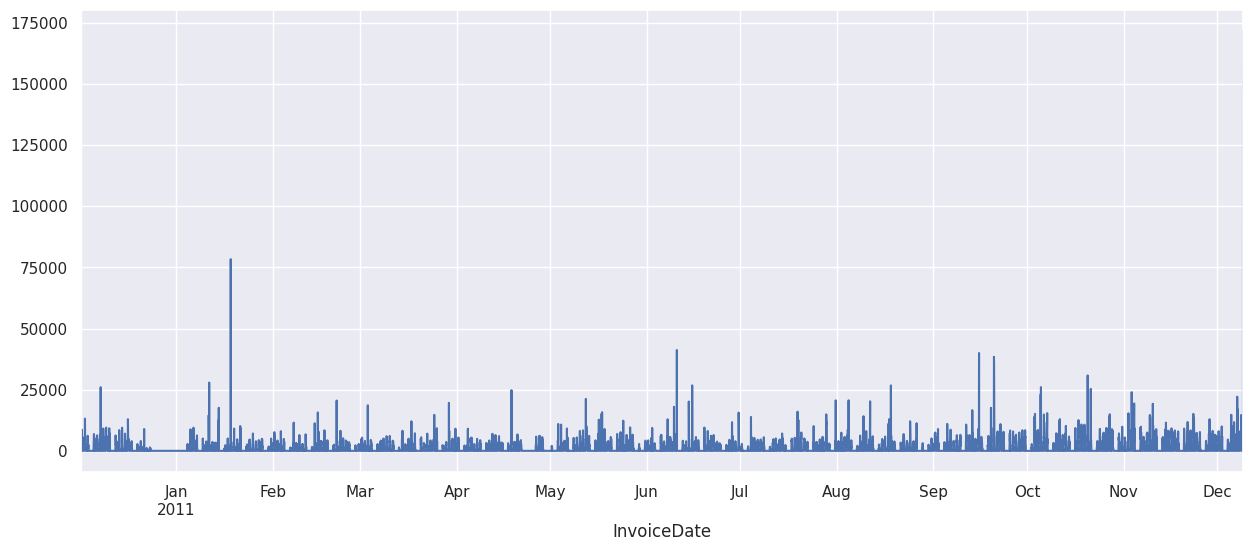

In [22]:
online_retail_data_table['TotalPrice'].resample('H').sum().plot(figsize=(15,6))

/tmp/ipykernel_640/2626896527.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  online_retail_data_table['TotalPrice'].resample('H').sum().plot(figsize=(15,6))


<Axes: xlabel='InvoiceDate'>

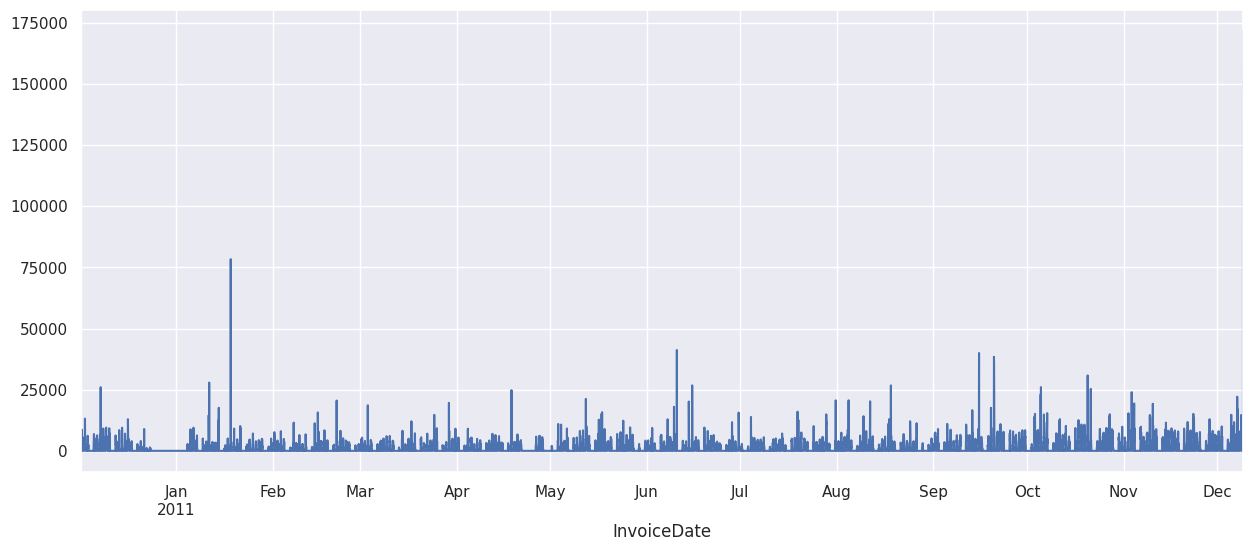

In [23]:
online_retail_data_table['TotalPrice'].resample('H').sum().plot(figsize=(15,6))

In [24]:
online_retail_data_table['TotalPrice'].resample('H').sum()[online_retail_data_table['TotalPrice'].resample('H').sum().max() == online_retail_data_table['TotalPrice'].resample('H').sum()]

/tmp/ipykernel_640/2012019410.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  online_retail_data_table['TotalPrice'].resample('H').sum()[online_retail_data_table['TotalPrice'].resample('H').sum().max() == online_retail_data_table['TotalPrice'].resample('H').sum()]


,TotalPrice
InvoiceDate,
2011-12-09 09:00:00,171679.08


The following data is filtered to focus on December 9, 2011, at 9 a.m. Pandas is useful since it is able to do this type of filtering.

In [25]:
online_retail_data_table.loc["2011-12-09 09"]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country,cancel_flg,TotalPrice
InvoiceDate,,,,,,,,,
2011-12-09 09:00:00,581479,22087,PAPER BUNTING WHITE LACE,10,2.95,17364,United Kingdom,5,29.50
2011-12-09 09:07:00,581480,23463,VINTAGE ZINC WATERING CAN,2,9.95,14441,United Kingdom,5,19.90
2011-12-09 09:07:00,581480,23464,VINTAGE ZINC WATERING CAN SMALL,4,4.95,14441,United Kingdom,5,19.80
2011-12-09 09:07:00,581480,22411,JUMBO SHOPPER VINTAGE RED PAISLEY,10,2.08,14441,United Kingdom,5,20.80
2011-12-09 09:07:00,581480,84029E,RED WOOLLY HOTTIE WHITE HEART.,8,4.25,14441,United Kingdom,5,34.00
2011-12-09 09:07:00,581480,22633,HAND WARMER UNION JACK,12,2.10,14441,United Kingdom,5,25.20
2011-12-09 09:07:00,581480,23355,HOT WATER BOTTLE KEEP CALM,12,4.95,14441,United Kingdom,5,59.40
2011-12-09 09:07:00,581480,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,12,4.25,14441,United Kingdom,5,51.00
2011-12-09 09:07:00,581480,22112,CHOCOLATE HOT WATER BOTTLE,6,4.95,14441,United Kingdom,5,29.70


From the results above, the product code with the highest sales is 23843, purchased by CustomerID 16446. This outcome was observed previously, and the data indicates that this customer purchased 80,995 units for only this product. However, it was speculated that this transaction might have been canceled.

In [26]:
online_retail_data_table[online_retail_data_table.StockCode==23843]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country,cancel_flg,TotalPrice
InvoiceDate,,,,,,,,,
2011-12-09 09:15:00,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446,United Kingdom,5,168469.6


For subsequent processing, the index is reset temporarily.

In [27]:
online_retail_data_table.reset_index(inplace=True)

Reference: Pandas has a feature called Pandas_Profiling, which automatically generates a simple data analysis report in HTML format for a given DataFrame. However, since this dataset is transaction data, you may get more meaningful results by filtering or processing the data to some extent before using Pandas_Profiling. (Note that if the index is not reset, an error may occur)

In [28]:
# Install Pandas-Profiling
!pip install https://github.com/ydataai/pandas-profiling/archive/master.zip

# Downgrading the Dependency Packages of Pandas-Profiling
!pip install markupsafe==2.0.1

     / 17.9 MB 14.6 MB/s 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 9.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 39.6 MB/s  0:00:00
  Created wheel for fg-data-profiling: filename=fg_data_profiling-0.0.dev0-py2.py3-none-any.whl size=400538 sha256=96bdfaa13ab4ab9a26cac637c6a1403386b4c17cb3b1c362d5c8297a5892dc76
  Stored in directory: /tmp/pip-ephem-wheel-cache-g3n5czzk/wheels/36/58/4d/1ed3e5bbd01e268bb52f96cd6f5dffeb6335f2c4035c624407
Successfully built fg-data-profiling
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [fg-data-profiling]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for markupsafe: filename=markupsafe-2.0.1-cp313-cp313-linux_x86_64.whl size=28676 sha256=b5f3d2002f9b5c17f15b7e746bd86b

In [29]:
import pandas_profiling as pdp
profile = pdp.ProfileReport(online_retail_data_table)
profile.to_file(output_file="/content/online_retail_data_table.html")

ModuleNotFoundError: No module named 'pandas_profiling'

In [ ]:
profile

#### <Practice Question 9-1-5>

Check if the Pareto principle (the top 20% of customers account for 80% of sales) applies.

#### Answer

In [ ]:
q_ten_cust_price_df = pd.qcut(cust_total_p_rank_df, 10, labels=['01','02','03','04','05','06','07','08','09','10'])

In [ ]:
merge_cust_df = pd.concat([cust_total_p_rank_df,q_ten_cust_price_df]
                              , axis=1
                              , join='inner')
merge_cust_df.columns = ['TotalPrice','Group']

In [ ]:
pd.DataFrame(merge_cust_df.groupby(["Group"])['TotalPrice'].sum() / merge_cust_df['TotalPrice'].sum()).cumsum() * 100

From the above results, it can be seen that the total sales ratio of segment groups 1 to 8 is 25%. Furthermore, the top 20% of segment groups 9 and 10 account for about 75%, which shows that the Pareto principle holds to some extent.

#### <Practice Question 9-1-6>

Let's conduct the decile analysis for time-series based on the above settings. Before performing the analysis, consider what can be inferred from it and first hypothesize. Then, visualize how many people moved from one segment to another. Was your hypothesis correct? What other findings might there be?

#### Answer

The most recent purchase date and the most recent maximum purchase date are as follows.

In [ ]:
online_retail_data_table.InvoiceDate.min()

In [ ]:
online_retail_data_table.InvoiceDate.max()

Let's divide the data into the first half and the second half. The period before July 31, 2011, will be considered the first half, and the period after that will be the second half.

In [ ]:
thred_date = datetime.datetime(2011,7,31)

In [ ]:
pre_online_retail_data_table = online_retail_data_table[online_retail_data_table.InvoiceDate<=thred_date]
pos_online_retail_data_table = online_retail_data_table[online_retail_data_table.InvoiceDate>thred_date]

Try the decile transition analysis on this data. To do the same thing twice, let's create a function. Also, each divided group is labeled and ranked from 1 to 10.

In [ ]:
def calc_decil_func(target_cust_df):
  cust_total_p_rank_df = target_cust_df.groupby(['CustomerID'])['TotalPrice'].sum().sort_values(ascending=False)
  q_ten_cust_price_df = pd.qcut(cust_total_p_rank_df, 10, labels=['01','02','03','04','05','06','07','08','09','10'])
  return q_ten_cust_price_df

In [ ]:
pre_q_ten_cust_price_df = calc_decil_func(pre_online_retail_data_table)
pos_q_ten_cust_price_df = calc_decil_func(pos_online_retail_data_table)

pre_q_ten_cust_price_df = calc_decil_func(pre_online_retail_data_table)
pos_q_ten_cust_price_df = calc_decil_func(pos_online_retail_data_table)

In [ ]:
merge_cust_prepos_df = pd.concat([pre_q_ten_cust_price_df, pos_q_ten_cust_price_df]
                              , axis=1
                              , join='inner')
merge_cust_prepos_df.columns = ['pre', 'pos']
merge_cust_prepos_df

Based on this data, by performing the following aggregation, you can understand how individuals from the first half (upper period) moved from one decile to another in the second half. By looking at this, you can see that most people remain in almost the same segment.

In [ ]:
merge_cust_prepos_df.groupby(['pre','pos'])['pos'].count().unstack()

To make it visually easier to understand, the following will display the data as a heatmap.

In [ ]:
plt.figure(figsize=(16,6))
sns.heatmap(merge_cust_prepos_df.groupby(['pre','pos'])['pos'].count().unstack(), cmap="Reds")

Visually, this makes it easier to understand, and we can see that the number of people is higher around Segment 10. This suggests that the business is successfully capturing valuable customers. On the other hand, there are still quite a few customers remaining in Segment 1, so it might be a good idea to consider a customer journey strategy to move these customers to higher segments.
This concludes the answer to the practice question. Here, we only tracked the movement of deciles numerically, but as mentioned earlier, it is important to implement initiatives aimed at moving customers up within a particular decile segment and then observe how they move in the next half-year, checking whether the number of people who moved up has increased, through experimentation and verification. Decile analysis and the subsequent RFM analysis cannot directly provide actionable insights just by themselves, so it's essential to be cautious.
Also, while we performed a simple analysis by dividing the periods, in many cases, analysis may require narrowing down the target group, such as including only people with IDs during a specific period across both the first and second half. In fact, this approach is more typical when examining changes in customer behavior, and how you design your analysis becomes crucial when performing such an analysis.

#### <Practice Question 9-1-7>

Extract only the products from group C.
Extract only the products from group B.
Focus on the two countries (Australia and Germany), conduct the ABC analysis for each, and examine if there are any differences between the AB groups.

In [ ]:
stock_total_p_rank_df = online_retail_data_table.groupby(['StockCode'])['TotalPrice'].sum().sort_values(ascending=False)
sample_df = stock_total_p_rank_df.sample(n=100)
sample_df.sort_values(ascending=False, inplace=True)

In [ ]:
!pip install abc_analysis

In [ ]:
from abc_analysis import abc_analysis, abc_plot
abc_analysis_result = abc_analysis(sample_df)

#### Answer

In [ ]:
print('The group of products from C is as follows.')
sample_df[sample_df<=abc_analysis_result['BCLimit']]

In [ ]:
print('The group of products from B is as follows.')
sample_df[(sample_df<abc_analysis_result['ABLimit'])&(sample_df>abc_analysis_result['BCLimit'])]

Let us calculate the total sales based on the product code and country. Note that purchasing data from e-commerce sites, for exmaple, is often represetned in a matrix like the one below, and is usually sparse (with many NaN values).

In [ ]:
s_c_tp_df = online_retail_data_table.groupby(['StockCode','Country'])['TotalPrice'].sum().unstack()
s_c_tp_df.head(20)

Next, let's create a function that takes the data table above and the country names as input and outputs the result of the ABC analysis.

In [ ]:
def country_abc_analysis(country_name, target_df):
  sample_df = target_df[country_name].dropna()
  abc_analysis_result = abc_analysis(sample_df)
  return abc_analysis_result

The data for both Australia and Germany is presented. Below is the data for Australia.

In [ ]:
abc_analysis_result_aud = country_abc_analysis('Australia', s_c_tp_df)
abc_plot(abc_analysis_result_aud)

Next is data for Germany.

In [ ]:
abc_analysis_result_aud = country_abc_analysis('Germany', s_c_tp_df)
abc_plot(abc_analysis_result_aud)

From the above comparison, it can be observed that in Australia, 40% of the products account for 80% of the sales, while in Germany, slightly over 30% of the products make up a similar proportion. This suggests that　products in Germany may be selling in a more concentrated manner.
Additionally, if there are any hypotheses or other perspectives, different from those in the practice questions, feel free to explore them.

#### <Practice Question 9-1-8>

Perform the RFM analysis by changing the thresholds in various ways.
Select several countries and perform the RFM analysis for each country.
(The implementation can be done by changing the thresholds or filtering the original data by selecting countries, so the answer is omitted.)

#### <Practice Question 9-1-9>

Below, without changing the definition of churn, please investigate whether there is any difference in the churn rate of customers (CustomerID) by country.

In [ ]:
merge_cust_prepos_df = pd.concat([pre_q_ten_cust_price_df, pos_q_ten_cust_price_df]
                              , axis=1
                              , join='outer')
merge_cust_prepos_df.columns = ['pre', 'pos']

#### Answer

The following checks which customer made purchases in which country. Some customers have made purchases in two countries, but since the number of such customers is small, they will be excluded from this analysis.

In [ ]:
cutum_country_cnt_df = online_retail_data_table.groupby(["CustomerID"])["Country"].nunique().sort_values(ascending=False)
cutum_country_cnt_df.head(10)

In [ ]:
exclude_id = cutum_country_cnt_df[:8].copy()
exclude_id.index

The following creaets the mapping data between `CustomerID` and `Country` after the exclusion process.

In [ ]:
cutum_country_df = online_retail_data_table[~online_retail_data_table["CustomerID"].isin(exclude_id.index)].groupby(["CustomerID","Country"])["Country"].nunique()
cutum_country_df.head(10)

Data preprocessing will be performed.

In [ ]:
merge_df2 = merge_cust_prepos_df.merge(cutum_country_df, left_index=True, right_index=True)
merge_df2.columns=["pre","pos","cnt"]
merge_df3 = merge_df2.reset_index()

Let's take a look at the United Kingdom.

In [ ]:
target_df = merge_df3[merge_df3.Country=="United Kingdom"]

In [ ]:
pre_count = target_df.pre.notnull().sum()
pos_churn_count = target_df[target_df.pre.notnull()].pos.isnull().sum()
print("churn ratio:{:.6f} %".format(pos_churn_count/pre_count * 100))

As expected, the United Kingdom has a large number of buyers, so the result is similar to the previous one. Now, let's simply iterate through and check the churn rate for each country. However, since the number of people is small, we will also include the absolute change in numbers for each country.

In [ ]:
for country in merge_df3.Country.unique():
  target_df = merge_df3[merge_df3.Country==country]
  pre_count = target_df.pre.notnull().sum()
  pos_churn_count = target_df[target_df.pre.notnull()].pos.isnull().sum()
  print(country+" | churn ratio:{0:.2f} %　| {1}=>{2}".format(pos_churn_count/pre_count * 100,pre_count,pos_churn_count))

Looking at the above results, France and Germany have smaller churn rates than the United Kingdom, but the sample size is too small, and the same applies to other countries. Therefore, please consider this only as a reference. Since this was done for practice, in practial terms, it might be one option not to focus too much on other countries.

####  <9-1.6 Comprehensive Question>

1. You have identified potential issues in data preprocessing from Section 11.4. Based on that, consider how to process the data and perform the analysis. Design and implement it. (There is no single correct answer.)

2. Using the data you determined in Step 1, perform a simple sales factor decomposition for December 2010. Calculate and display the following metrics: the number of purchasing customers (corporate clients), the average total purchase amount per client, and the average number of purchases per client (basket average).

3. For the data you judged in Step 1, calculate and display the following metrics for each month from January 2011 to November 2011: the number of purchasing customers (corporate clients), the average total purchase amount per client, and the average number of purchases per client (basket average). What can you infer from this?

4. Perform other sales factor decompositions and develop hypotheses. Try to verify these hypotheses.

5. Combine the analysis methods you've used so far (such as decile analysis, ABC analysis, etc.) to design an analysis. Implement them and consider what approaches can be taken for each segment. Additionally, think about what data would be needed for certain analyses, how you would implement actions, conduct experiments, and verify results. You may generate hypothetical data (e.g., customer website access data, product master data, data from a random selection of customers who received a costly direct mail over a set period, etc.).

#### Answer

It is possible to remove canceled records by performing a JOIN or similar operations, but it may take too long. Therefore, in this case, we'll focus on the fact that the canceled quantities are negative. For the sales amount, we will include the canceled quantities in the aggregation, as the final result will reflect the offset. So, we will use the data as it is.

In [ ]:
tmp_online_retail_data_table['TotalPrice'] = tmp_online_retail_data_table.Quantity * tmp_online_retail_data_table.UnitPrice

We will set `InvoiceDate` as the index to perform time series processing.

In [ ]:
tmp_online_retail_data_table.set_index("InvoiceDate", inplace=True)

In [ ]:
tmp_online_retail_data_table.info()

Looking at the following, it can be seen that the sales anomaly in December 2011 was offset and eliminated by the cancellation records.

In [ ]:
tmp_online_retail_data_table['TotalPrice'].resample('D').sum().plot(figsize=(15,6))

As explained earlier, strictly speaking, purchases made before December 2010 might have been canceled, and only the cancellation data is present in the current data. It is quite difficult to appropriately remove this data. Additionally, orders placed later, such as in December 2011, could be canceled in 2012 or beyond, but it is challenging to determine this based on the calculation reference date.

Next, let's take a look at the purchasing data for the corporation with `CustomerID` 15749 as a sample.

In [ ]:
tmp_online_retail_data_table[(tmp_online_retail_data_table.CustomerID==15749)]

From the data above, it seems that the purchase made in January 2011 was canceled on April 18, 2011, and the same item was purchased again on the same day. Looking closely at the prices of these purchases, it appears that the price has decreased, which is likely why the item was repurchased. While it’s not ideal, the item "47566B TEA TIME PARTY BUNTING" was canceled, but it seems the correct item to cancel should have been "47556B TEA TIME TEA TOWELS" instead. Since this is a corporate purchase, it’s possible that the person in charge made a data entry mistake.
As data analysts, we often encounter such cases, but correcting all of them can be very time-consuming. For this course, we'll skip such corrections, assuming that these cases are rare (about 2% or fewer) and do not significantly impact the analysis. Therefore, we will proceed as is.

In [ ]:
tmp_online_retail_data_table.cancel_flg.value_counts()/tmp_online_retail_data_table.cancel_flg.count() * 100

As mentioned earlier, ideally, the canceled InvoiceNo should be linked to the original InvoiceNo of the order. Since the data does not follow this structure, the person responsible for data preprocessing will face significant challenges. In the example above, there was a hypothesis that a manual data entry mistake might have occurred, but this is not about blaming the person who made the mistake. The key point is to create a system that eliminates such errors, such as using a system where past orders can only be selected from a dropdown list rather than allowing free manual input.
Moving forward, the focus should be on designing and developing systems that ensure proper logging of data, so that issues like these do not arise. Instead of spending time fixing these issues one by one, it is wiser to take a long-term perspective and consider data management as part of a broader data strategy. This approach will help avoid encountering these troublesome cases in the future.

Now, let's perform the sales factor decomposition by calculating the monthly unique customer count, average sales amount, and average basket count.

Since it's December 2010, the calculation is done as follows.

In [ ]:
target_df = tmp_online_retail_data_table[tmp_online_retail_data_table.index< datetime.datetime(2011,1,1)]

In [ ]:
print("Cnt ID:{0}".format(target_df["CustomerID"].nunique()))
print("Avg Revenue:{0:.2f}".format(target_df["TotalPrice"].sum()/target_df["CustomerID"].nunique()))
print("Avg Busket:{0:.2f}".format(target_df["InvoiceNo"].nunique()/target_df["CustomerID"].nunique()))

Next, let's calculate for the months from January 2011 to November 2011 all at once.

In [ ]:
st_dt = datetime.datetime(2011,1,1)
end_dt = datetime.datetime(2011,11,30)

In [ ]:
target_df = tmp_online_retail_data_table[(tmp_online_retail_data_table.index>=st_dt)&(tmp_online_retail_data_table.index<=end_dt)]

Here is the number of unique customers per month.

In [ ]:
plt.figure(figsize=(16,8))
plt.plot(target_df["CustomerID"].resample('M').nunique())

Next is the trend of revenue per customer per month. It seems to have dropped in May 2011, but overall, it is growing.

In [ ]:
plt.figure(figsize=(16,8))
plt.plot(target_df["TotalPrice"].resample('M').sum() / target_df["CustomerID"].resample('M').nunique())

Next is the trend of the number of baskets per customer per month. Looking at this, it appears to be gradually incrasing, but we can see that most customers are buying only 1 or 2 baskets.

In [ ]:
plt.plot(target_df["InvoiceNo"].resample('M').nunique()/target_df["CustomerID"].resample('M').nunique())

From the above results, we can see that the number of companies is gradually increasing, and both the purchase amount per customer and the number of baskets are also growing according to this time series data.
As for exercises 4 and 5, there is no fixed answer. However, what is more important than the answer itself is the thinking process, so please be sure to give them a try.